# Linear regression

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Exercise 1: OLS linear regression
The analytical solution of OLS least squares is given by:
$$\mathbf{w} = (\mathbf{X}^{\rm T}\mathbf{X})^{-1} \mathbf{X}^{\rm T}\mathbf{y}$$
The mean squared error (MSE) cost function is given by:
$$L(\mathbf{w}) = \frac{1}{N}\sum_{i=1}^N \|\mathbf{w}\mathbf{x}_i - y_i \|^2$$

1. Visualize the dataset using a scatter plot.
1. Compute the weights $\mathbf{w}$ using numpy.
1. Visualize the learned line in the scatter plot. 
1. Compute the MSE using numpy.
1. Compare your weights and MSE to the numpy function `np.linalg.lstsq()`.

In [2]:
def make_dataset1(N=300, slope=1.3, intercept=0.5, noise=0.5, seed=42):
    rng = np.random.default_rng(seed)
    x = rng.normal(0.0, 1.0, N)
    y = slope * x + intercept + rng.normal(0.0, noise, N)
    X = np.column_stack((np.ones(N), x))
    return X, y

X, y = make_dataset1()

Text(0.5, 1.0, 'MSE: 0.26')

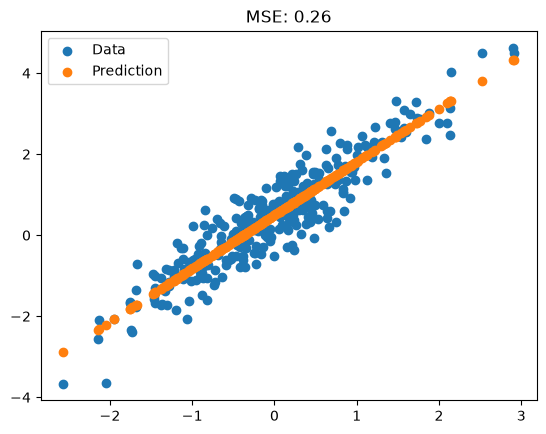

In [3]:
plt.scatter(X[:, 1], y, label="Data")

W = np.linalg.inv(X.T @ X) @ X.T @ y

preds = W @ X.T

plt.scatter(X[:,1], preds, label="Prediction")
plt.legend()

plt.title(f"MSE: {np.mean(np.square(preds - y)):.2f}")

In [4]:
np_W = np.linalg.lstsq(X, y)[:1]

print(np_W, W)

f"NP MSE: {np.mean(np.square(np_W @ X.T - y))}"

(array([0.49510513, 1.31779628]),) [0.49510513 1.31779628]


'NP MSE: 0.2573431207792485'

## Exercise 2: The role of outliers in OLS linear regression

1. Visualize the dataset using a scatter plot.
1. Compute the weights $\mathbf{w}$.
1. Visualize the learned line in the scatter plot.
1. What do you observe?

In [5]:
def make_dataset2(N=300, slope=1.3, intercept=0.5, noise=0.5, seed=42):
    rng = np.random.default_rng(seed)
    x = rng.normal(0.0, 1.0, N)
    x[-1] = 42
    y = slope * x + intercept + rng.normal(0.0, noise, N)
    y[-1] = 12
    X = np.column_stack((np.ones(N), x))
    return X, y

X, y = make_dataset2()

Text(0.5, 1.0, 'MSE: 1.07')

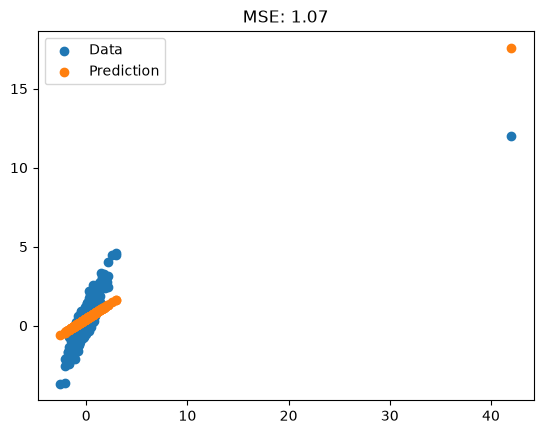

In [6]:
plt.scatter(X[:, 1], y, label="Data")

W = np.linalg.inv(X.T @ X) @ X.T @ y

preds = W @ X.T

plt.scatter(X[:,1], preds, label="Prediction")
plt.legend()

plt.title(f"MSE: {np.mean(np.square(preds - y)):.2f}")

The single outlier heavily influences the slope of the prediction.

## Exercise 3: Basis functions

What if our data does not follow a straight line? Linear regression can learn non-linear functions when using non-linear basis functions. Basis functions $\phi(x)$ are a simple (non-linear) preprocessing of your features. If we can make an educated guess about the function underlying the data, we can use non-linear basis functions to learn the parameters of these non-linear functions with linear regression.

1. Visualize the dataset using a scatter plot and add the ground truth. **Hint:** Inspect the `make_dataset3()` function.
1. Compute the weights $\mathbf{w}$ of a standard OLS linear regression and plot the line in the scatterplot.
1. Now preprocess the data using $\phi(x)=sin(x)$.
1. Compute the weights $\mathbf{w}$ of the kernel OLS linear regression and plot the line in the scatterplot.

In [22]:
def make_dataset3(N, seed=42):
    rng = np.random.default_rng(seed)
    x = np.linspace(0, 3 * np.pi, N)
    y = 2 + 6 * np.sin(x)
    y += rng.normal(0, 1, N)
    X = np.column_stack((np.ones(N), x))
    return X, y

N = 50
X, y = make_dataset3(N)

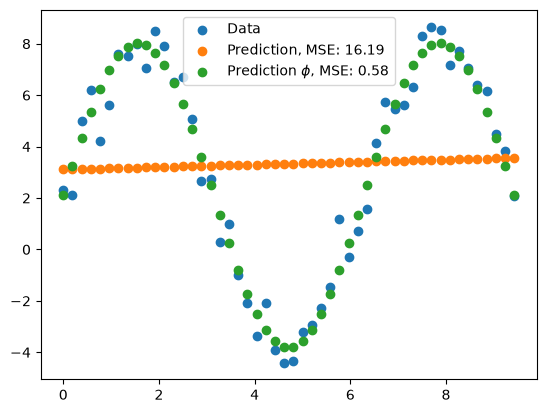

In [23]:
plt.scatter(X[:, 1], y, label="Data")

W = np.linalg.inv(X.T @ X) @ X.T @ y
preds = W @ X.T
plt.scatter(X[:,1], preds, label=f"Prediction, MSE: {np.mean(np.square(preds - y)):.2f}")

phi = np.column_stack([np.ones_like(X), np.sin(X)])
w, *_ = np.linalg.lstsq(phi, y)    

preds = phi @ w

plt.scatter(X[:,1], preds, label=f"Prediction $\phi$, MSE: {np.mean(np.square(preds - y)):.2f}")

plt.legend()

## Exercise 4: Polynomial regression

Coming up with suitable basis functions can be challenging and time-consuming. Is there another way to learn linear models that fit non-linear basis functions? Yes: polynomial regression.

In plain linear regression, we learn weights such that we fit a linear function: $f(\mathbf{x},\mathbf{w}) = \mathbf{w}^T\mathbf{x}$. With non-linear basis functions, we **replace** our feature(s) to learn a linear model that can fit non-linear functions: $f(\mathbf{x},\mathbf{w})=\mathbf{w}^T\phi(\mathbf{x})$. 

Here, we abuse the fact that you can approximate any continuous function (defined on a closed interval) by a polynomial function. Furthermore, we could also **add** features instead of **replacing** our features with the preprocessed features. In polynomial regression, we learn a polynomial function (the clue is in the name). This means we learn a function of the shape $f(x,\mathbf{w}) = w_0 + w_1x + w_2x^2 + ... + w_Mx^M = \sum_{j=0}^M w_jx^j$, where $M$ is the order of the polynomial. We can view it as using $M+1$ basis functions: $\phi_j(x) = x^j$ to write $f(x,\mathbf{w}) = \mathbf{w}^T\boldsymbol{\phi}(x)$. If we apply these basis functions $\boldsymbol{\phi}$ to our data, we obtain our preprocessed data $\Phi$. This matrix $\Phi$ is known in the literature as a *design matrix*. What is cool is that we can simply use this design matrix $\Phi$ instead of our data matrix $X$ in the analytical solution (equation 1 at the beginning of this notebook) to estimate the parameters of the model that minimise the MSE! 

1. Visualize the dataset using a scatter plot and add the ground truth. **Hint:** Inspect the `make_dataset4()` function.
1. Compute the weights $\mathbf{w}$ of a standard OLS linear regression and plot the line in the scatterplot.
1. Define a function `generate_phi(x, M)` that takes a feature `x` and the number of polynomials `M`, and generates the design matrix.
1. Compute the weights $\mathbf{w}$ of the polynomial OLS linear regression and plot the line in the scatterplot. Do so for `M=[0, 1, 3, 9, 15]`.
1. What happens when $M=0$?
1. What happens when $M=1$?
1. What happens when $M=15$?
1. How could we find a suitable order $M$ for our polynomial, given that $M$ is a hyperparameter? 
1. What would happen if you predict a datapoint outside the range of the training data?

In [25]:
def generate_dataset4(N, seed=42):
    rng = np.random.default_rng(seed)
    x = np.linspace(0, 3 * np.pi, N)
    y = 2 + 5 * np.cos(x)
    y += rng.normal(0, 1, N)
    X = np.column_stack((np.ones(N), x))
    return X, y

N = 20
X, y = generate_dataset4(N)

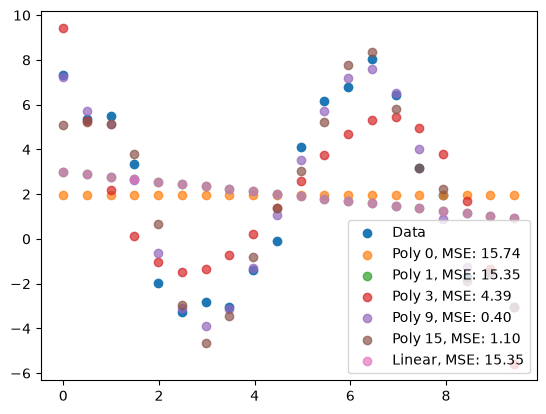

In [40]:
plt.scatter(X[:, 1], y, label="Data")

def generate_phi(x, M):
    return np.column_stack([np.power(x, m) for m in range(M+1)])

for M in [0, 1, 3, 9, 15]:
    phi = generate_phi(X, M)
    w, *_ = np.linalg.lstsq(phi, y) 
    print()
    preds = w @ phi.T
    plt.scatter(X[:,1], preds, label=f"Poly {M}, MSE: {np.mean(np.square(preds - y)):.2f}", alpha=0.7)


W = np.linalg.inv(X.T @ X) @ X.T @ y
preds = W @ X.T
plt.scatter(X[:,1], preds, label=f"Linear, MSE: {np.mean(np.square(preds - y)):.2f}", alpha=0.7)


plt.legend()

5. At $M = 0$, the formula becomes $w_0x_0$ ie. a flat line with only an intercept.
6. At $M=1$, the formula becomes $w_0x_0 + w_1x_1$ ie. a linear regression.
7. At $M=15$, too many polynomial are included which lowers the accuracy
8. We can apply nested cross validation to find the best value for $M$.
9. 